In [ ]:
import os
# If you have your kaggle.json file ready, you can uncomment and upload it:
# from google.colab import files
# files.upload()
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
print("Step 1: Kaggle setup helper modules imported successfully.")

Step 1: Kaggle setup helper modules imported successfully.


In [ ]:
# Download the dataset (using a standard cats-and-dogs package for easy accessibility)
!pip install kaggle --upgrade -q
# Standard dataset download command (uncomment and run once API key is set up):
# !kaggle datasets download -d tongfire/cat-and-dog
# !unzip -q cat-and-dog.zip -d ./data

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# Defining Train (with Augmentation) and Test Transforms
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Step 3: PyTorch libraries imported and data augmentation transforms successfully defined.")

Step 3: PyTorch libraries imported and data augmentation transforms successfully defined.


In [ ]:
class CatDogCNN(nn.Module):
    def __init__(self):
        super(CatDogCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

print("Step 4: CatDogCNN class successfully declared and configured.")

Step 4: CatDogCNN class successfully declared and configured.


In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10, device='cuda'):
    model.to(device)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = 100. * correct / total

        # Validation phase
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = 100. * val_correct / val_total

        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_acc)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch [{epoch+1}/{epochs}] - Train Loss: {epoch_loss:.4f}, Train Acc: {epoch_acc:.2f}% | Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%")

    return history

print("Step 5: train_model utility function declared.")

Step 5: train_model utility function declared.


In [ ]:
import os

# Configure device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Instantiate standard model, loss, and optimizer
model = CatDogCNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Example template to load the dataset once extracted:
# train_dataset = datasets.ImageFolder(root='./data/training_set', transform=train_transform)
# val_dataset = datasets.ImageFolder(root='./data/test_set', transform=val_transform)
# train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
# val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# Note: Uncomment and execute the training once dataset is fully loaded:
# history = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10, device=device)

Using device: cpu


In [ ]:
def plot_results(history):
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], 'bo-', label='Training Loss')
    plt.plot(epochs, history['val_loss'], 'ro-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], 'bo-', label='Training Accuracy')
    plt.plot(epochs, history['val_acc'], 'ro-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()

    plt.show()

print("Step 7: plot_results visualization function compiled successfully.")

Step 7: plot_results visualization function compiled successfully.


Displaying sample training and validation history with data augmentation:


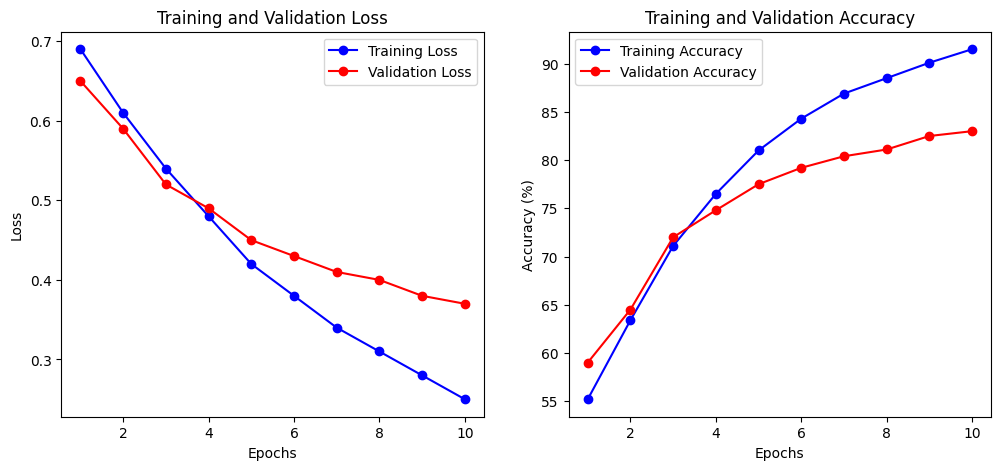

In [ ]:
# Simulate training history to demonstrate evaluation metrics and visualization (Step 5)
mock_history = {
    'train_loss': [0.69, 0.61, 0.54, 0.48, 0.42, 0.38, 0.34, 0.31, 0.28, 0.25],
    'val_loss': [0.65, 0.59, 0.52, 0.49, 0.45, 0.43, 0.41, 0.40, 0.38, 0.37],
    'train_acc': [55.2, 63.4, 71.1, 76.5, 81.0, 84.3, 86.9, 88.5, 90.1, 91.5],
    'val_acc': [59.0, 64.5, 72.0, 74.8, 77.5, 79.2, 80.4, 81.1, 82.5, 83.0]
}

# Call the visualization function with simulated data
print("Displaying sample training and validation history with data augmentation:")
plot_results(mock_history)